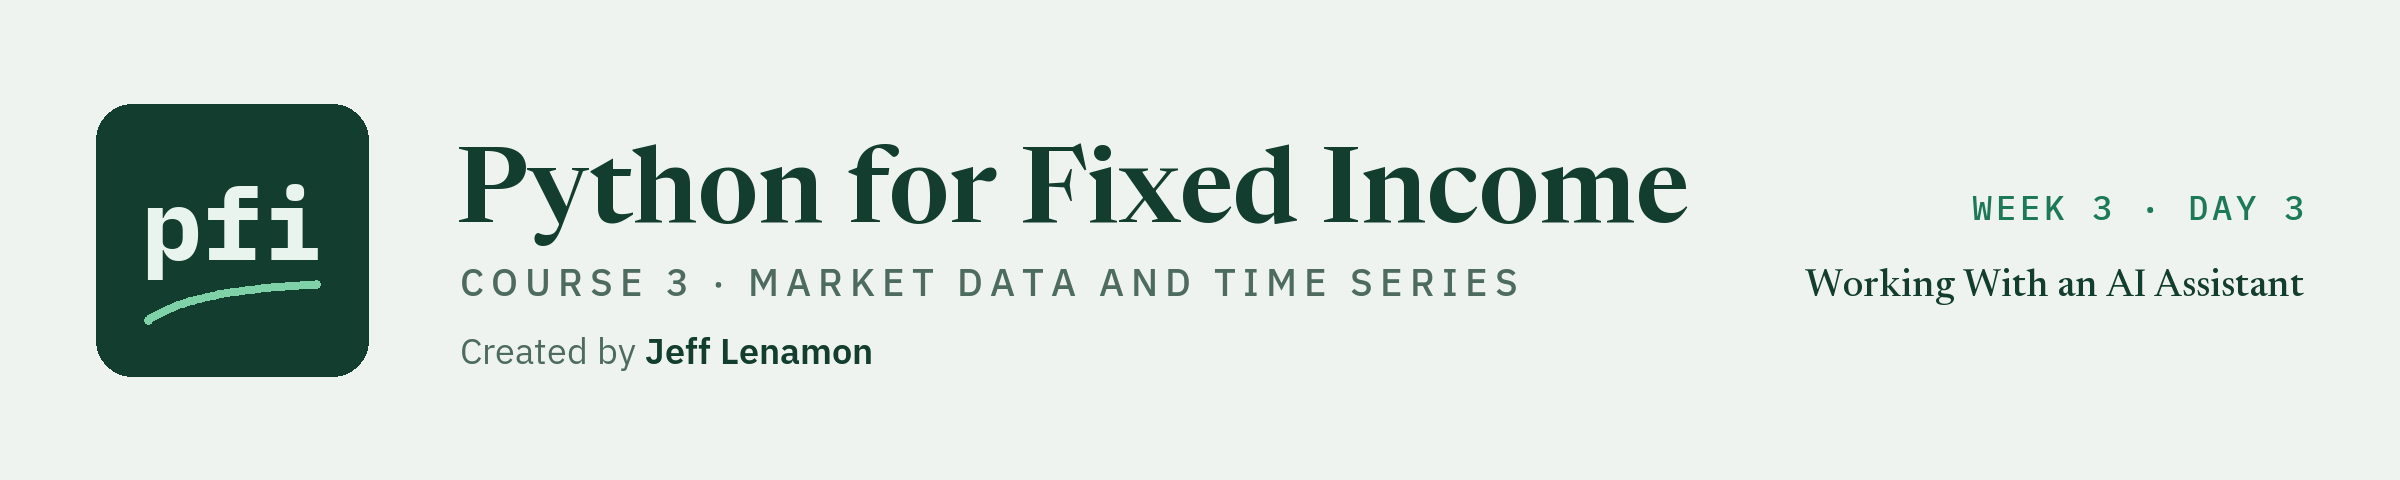

# Working With an AI Assistant

Week 3, Day 3. An assistant's "this passes your test" checked with tests you run: three pandas answers, a chart, a DV01, what may go into the chat, a package that does not exist, JSON replies read by `parse_json_reply`, and a patch reviewed with Git.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day3/13_working_with_an_ai_assistant.ipynb)

### The Desk Lead's Note

> A colleague has been using an AI assistant and forwards what it wrote, each piece signed off "this passes your test": three pandas functions, a 2s10s chart for the morning note, a formula for "percent of days at or below", and a DV01 function. It also recommends a package. Before any of it reaches the desk: tell me which pieces are right, each with a test you ran yourself. Write down what we may paste when we ask it for help. Give `marketdata` one function that checks a reply we asked for as JSON. Last, it offered a patch to our `marketdata.py`: do we take it?

No AI tool, key, or network is used today: every "assistant answer" was written for this course in the style of an AI assistant's answer, labelled so, and no vendor is named.
Course 1's table of what never goes into an AI tool still holds, and your firm's policy comes first.

**An assistant's "this passes" is a claim; the test you run is the answer.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 12 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(13)

Work folder pfi_course3_13_k4w7q2xr: 8 data files, Course 2's bondmath.py, marketdata.py as notebook 12 left it, 12 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................................                         [100%]
48 passed in 0.50s



### Imports and the Curve

In [3]:
import importlib
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath
import marketdata as md

# the curve in percent, and Excel's values for each market day of 2026 (round_trip: notebook 05)
curve = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                    float_precision='round_trip')
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')
print(f'{len(curve):,} market days of yields in percent; {len(reference)} reference rows of 2026')

2,940 market days of yields in percent; 190 reference rows of 2026


## 13.1 The Prompt Is a Spec

![Three boxes, the docstring with what comes back, its units and its convention, the conventions the course's rules that apply, and the test the numbers the answer must give, pasted into one prompt. The prompt goes to the assistant; the reply comes back with code and the words this passes your test, in a dashed box. An arrow from the reply back to the test: you run the test yourself](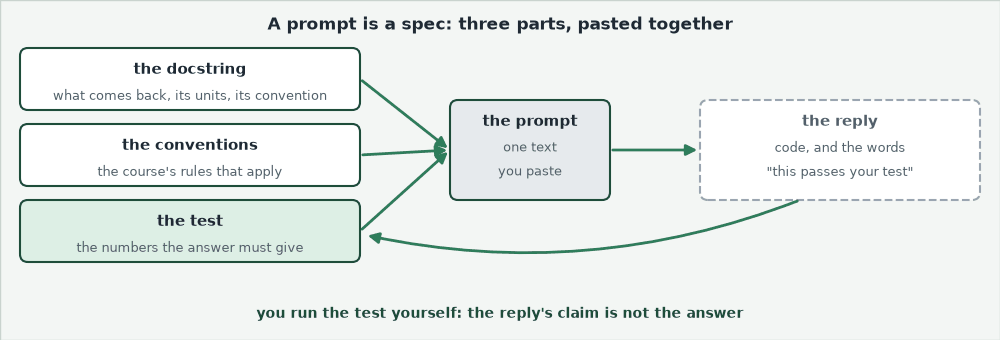)

Course 1's Working With an AI Assistant said to ask with what you have, what you want, and the units.
That sentence starts a prompt.
A **spec** is all of it: the docstring, the conventions that apply, and a test, pasted together.
Every AI check since Course 2 has used one: the docstring is the prompt.

### Three Parts, Pasted Together

Q. Write the prompt for a function that returns month-end levels.

In [4]:
# 1. the docstring: what comes back, in what units, by which convention, with two dates as proof
DOCSTRING = '''month_end_levels(series): the last observation of each calendar month, labelled by
the date of that observation. Units: unchanged (a yield in percent stays in percent).
September 2026 is 2026-09-30, and January 2026 is 2026-01-30 (the 31st was a Saturday).'''
# 2. the course's conventions that apply
CONVENTIONS = '''The market's days are the rows of the data, not a holiday calendar.
A period's value is its last observation, labelled by that observation's own date.'''

In [5]:
# 3. the test the answer must pass
TEST = """result = month_end_levels(curve['10 Yr'].loc['2026'])
assert result.loc['2026-09-30'] == 5.29, 'September is wrong'
january = result.index[0]
assert january == pd.Timestamp('2026-01-30'), f'January is labelled {january.date()}'"""
parts = ['Write a Python function with pandas only.', DOCSTRING,
         'Follow these conventions:\n' + CONVENTIONS, 'It must pass this test:\n' + TEST]
# '\n\n'.join puts a blank line between the parts
print('\n\n'.join(parts))

Write a Python function with pandas only.

month_end_levels(series): the last observation of each calendar month, labelled by
the date of that observation. Units: unchanged (a yield in percent stays in percent).
September 2026 is 2026-09-30, and January 2026 is 2026-01-30 (the 31st was a Saturday).

Follow these conventions:
The market's days are the rows of the data, not a holiday calendar.
A period's value is its last observation, labelled by that observation's own date.

It must pass this test:
result = month_end_levels(curve['10 Yr'].loc['2026'])
assert result.loc['2026-09-30'] == 5.29, 'September is wrong'
january = result.index[0]
assert january == pd.Timestamp('2026-01-30'), f'January is labelled {january.date()}'


Nothing in it comes from a real book, and nothing is secret: public Treasury data and the course's rules.

**The prompt decides every choice in writing, and its test is the review you run yourself.**

## 13.2 Three Answers, Each Run Against a Test

Three answers came back to prompts built that way.
Each ran without an error, and each said it passed.

### Answer A: "This Passes Your Test"

Q. Run the prompt's test yourself.

In [6]:
# Answer A: written for this course in the style of an AI assistant's answer
def month_end_levels(series):
    """The last observation of each calendar month, labelled by the date of that observation."""
    # resample to month ends and keep the last value in each month
    return series.resample('ME').last()

In [7]:
# the prompt's test, run by you
result = month_end_levels(curve['10 Yr'].loc['2026'])
assert result.loc['2026-09-30'] == 5.29, 'September is wrong'
january = result.index[0]
assert january == pd.Timestamp('2026-01-30'), f'January is labelled {january.date()}'

AssertionError: January is labelled 2026-01-31

Notebook 04's trap: `resample('ME')` labels a month by its last calendar day, here a Saturday with no row.
September passed, because 30 September is a market day: a test on one easy date would have let it through.
The fix is a function you own, `md.last_per_period(series, 'ME')`.

### Answer B: 2s10s and Its Daily Change, Against Excel and Your Functions

In [8]:
# Answer B: written for this course in the style of an AI assistant's answer
def slope_and_change(curve):
    """2s10s in bp (10 Yr less 2 Yr, times 100) and its change from the previous row, in bp."""
    table = pd.DataFrame({'slope_2s10s_bp': (curve['10 Yr'] - curve['2 Yr']) * 100})
    # the slope is already in bp, so its change is a plain difference
    table['chg_1d_bp'] = table['slope_2s10s_bp'].diff()
    return table

In [9]:
answer_b = slope_and_change(curve)
slope_2026_b = answer_b['slope_2s10s_bp'].loc[reference.index]
gap_excel = (slope_2026_b - reference['slope_2s10s_bp']).abs().max()
# notebook 09's slope, then notebook 06's change of a series already in bp
expected = md.change_bp(md.slope_bp(curve, '2 Yr', '10 Yr'), percent_units=False)
gap_mine = (answer_b['chg_1d_bp'] - expected).abs().max()
assert gap_excel <= 1e-9 and gap_mine <= 1e-9
print(f'largest gap: {gap_excel:.1e} bp from Excel, {gap_mine:.1e} bp from change_bp')

largest gap: 0.0e+00 bp from Excel, 0.0e+00 bp from change_bp


**Excel side by side.** The reference sheet has the 2 Yr in column B and the 10 Yr in D.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">2s10s in bp</td><td align="left"><code>answer_b['slope_2s10s_bp']</code></td><td align="left"><code>=(D262-B262)*100</code>, filled down</td><td align="left">190 rows, gap 0.0 bp</td></tr>
</table>
<br clear="left">

Not every answer is wrong: the test tells you which to keep.

### The Same Review on a Formula

Asked in Excel for "the percent of the last 252 days at or below today's 10-year yield", an assistant suggested `PERCENTRANK.INC`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Share at or below, the course's measure</td><td align="left"><code>md.rolling_percentile_rank(curve['10 Yr'], 252)</code></td><td align="left"><code>=COUNTIF(D200:D451,"&lt;="&amp;D451)/COUNT(D200:D451)*100</code>, the 252 rows to 2026-10-02</td><td align="left">99.60317460317461</td></tr>
<tr><td align="left">The assistant's suggestion</td><td align="left">none</td><td align="left"><code>=PERCENTRANK.INC(D200:D451,D451)</code></td><td align="left">0.996</td></tr>
</table>
<br clear="left">

Q. They agree on the last day. Do they agree on every 2026 reference row?

In [10]:
mine = md.rolling_percentile_rank(curve['10 Yr'], 252).loc[reference.index]
gap_countif = (mine - reference['pctrank252_10y']).abs()
# PERCENTRANK.INC returns a fraction: times 100 to compare in percent
gap_suggestion = (mine - reference['percentrank_inc252_10y'] * 100).abs()
print(f'COUNTIF: largest gap {gap_countif.max():.1e} points')
print(f'PERCENTRANK.INC: differs on {(gap_suggestion > 1e-9).sum()} of {len(mine)} rows, '
      f'by up to {gap_suggestion.max():.2f} points on {gap_suggestion.idxmax().date()}')

COUNTIF: largest gap 0.0e+00 points
PERCENTRANK.INC: differs on 172 of 190 rows, by up to 5.02 points on 2026-04-20


Notebook 08's 8.4 showed why: `PERCENTRANK.INC` counts the values strictly below, over n - 1.
A suggested formula can run, return a number in the right range, and measure something else.

### Answer C: 21-Row Volatility, Against Excel's `STDEV.S`

The prompt asked for the sample standard deviation of the 10 Yr's daily changes in bp, with no value until the window is full.

In [11]:
# Answer C: written for this course in the style of an AI assistant's answer
def vol_21_bp(changes_bp):
    """21-row volatility of daily changes in bp: sample standard deviation, min_periods = 21."""
    # min_periods=5 so the series starts sooner and the chart has no gap at the start
    return changes_bp.rolling(21, min_periods=5).std()

In [12]:
# daily changes of the 10 Yr in bp; the first row has no row before it, so it is dropped
changes_10y = md.change_bp(curve['10 Yr']).dropna()
answer_c = vol_21_bp(changes_10y)
gap = (answer_c.loc[reference.index] - reference['vol21_10y_bp']).abs().max()
assert gap <= 1e-9
print(f'largest gap from Excel over the 190 rows of 2026: {gap:.1e} bp')

largest gap from Excel over the 190 rows of 2026: 2.4e-14 bp


**Predict 1**

Q. Answer C passes on 2026, and its comment says `min_periods=5`. Over the 10 Yr's daily changes from 2015, how many values does it give before 21 changes exist? Write down a number.

### Against `rolling_vol_bp` From the First Row

In [13]:
# notebook 07's function: nothing until the window is full
expected = md.rolling_vol_bp(changes_10y, window=21)
partial = (answer_c.notna() & expected.isna()).sum()
assert partial == 0, f'{partial} values from windows of fewer than 21 rows'

AssertionError: 16 values from windows of fewer than 21 rows

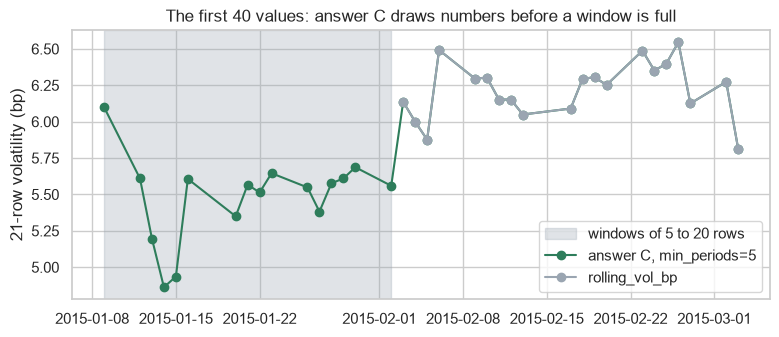

In [14]:
start = answer_c.head(40)
fig, ax = plt.subplots(figsize=(9, 3.5))
# notebook 03's axvspan shades the dates of the windows of 5 to 20 rows
ax.axvspan(start.index[4], start.index[19], color='#9AA5B1', alpha=0.3,
           label='windows of 5 to 20 rows')
ax.plot(start.index, start, marker='o', label='answer C, min_periods=5')
ax.plot(start.index, expected.head(40), marker='o', label='rolling_vol_bp')
ax.set_title('The first 40 values: answer C draws numbers before a window is full')
ax.set_ylabel('21-row volatility (bp)')
ax.legend(loc='lower right')
plt.show()

The 2026 rows matched Excel, so a test on 2026 alone passed.
The fix is `md.rolling_vol_bp(changes_10y, window=21)`.

**Excel side by side.** The daily changes in column F.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">21-row volatility in bp</td><td align="left"><code>answer_c</code></td><td align="left"><code>=STDEV.S(F242:F262)</code>, filled down</td><td align="left">190 rows of 2026, gap 2.4e-14 bp</td></tr>
</table>
<br clear="left">

**Three answers ran without an error: one labels by the calendar, one is right, and one is wrong only at the start, where a test on 2026 never looks.**

## 13.3 A Chart That Looks Finished

A number can be tested; a chart looks finished.
The prompt asked for 2s10s over 2026, in bp, with the unit on the axis.

### Draw the Assistant's Chart

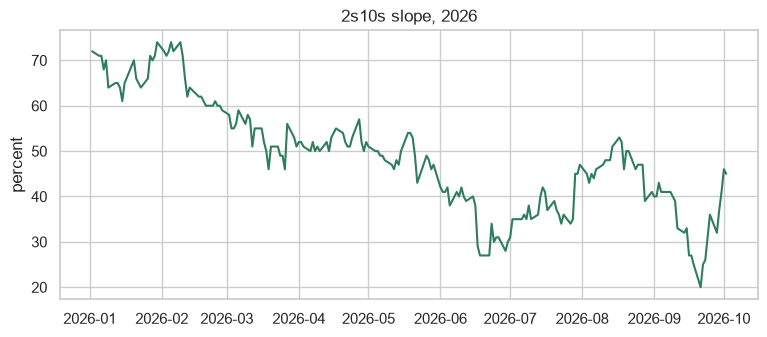

In [15]:
# written for this course in the style of an AI assistant's answer
def plot_2s10s(curve):
    """Line chart of the 2s10s slope in bp (10 Yr less 2 Yr, times 100), its unit on the y axis."""
    slope = (curve['10 Yr'] - curve['2 Yr']) * 100
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(slope.index, slope)
    ax.set_title('2s10s slope, 2026')
    ax.set_ylabel('percent')
    return fig, ax


fig, ax = plot_2s10s(curve.loc['2026'])
plt.show()

`plot_2s10s` returns the figure and its axes, so the next cell can read them.

### Read the Chart Object, Then Check It

In [16]:
def check_chart(ax, series, unit):
    """Stop unless the y axis names the unit and the first line draws exactly the series."""
    label = ax.get_ylabel()
    assert unit in label, f'the y axis says {label!r}, but the data is in {unit}'
    # ax.lines holds the lines drawn; get_ydata() gives the numbers a line draws
    drawn = ax.lines[0].get_ydata()
    assert len(drawn) == len(series) and (abs(drawn - series.to_numpy()) <= 1e-9).all()

In [17]:
# the numbers behind the chart, from your own function
slope_2026 = md.slope_bp(curve.loc['2026'], '2 Yr', '10 Yr')
check_chart(ax, slope_2026, 'bp')

AssertionError: the y axis says 'percent', but the data is in bp

The line is right and the word is wrong: a reader takes the last point, 45, as 45 percent.

### Fix the Label, Check Again

checked: bp on the axis, last point 45.0 bp on 2026-10-02


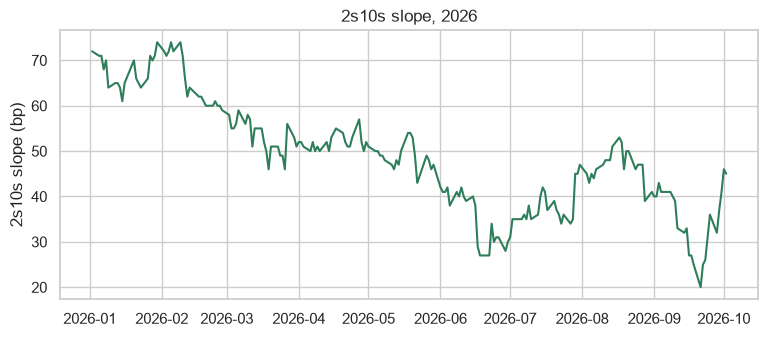

In [18]:
fig, ax = plot_2s10s(curve.loc['2026'])
ax.set_ylabel('2s10s slope (bp)')
check_chart(ax, slope_2026, 'bp')
last_day = slope_2026.index[-1].date()
print(f'checked: bp on the axis, last point {slope_2026.iloc[-1]:.1f} bp on {last_day}')
plt.show()

**A chart cannot raise an error for a wrong word: read its label and its line as data, and "looks right" becomes a test.**

## 13.4 An Assistant's DV01 Against Your `bondmath`

Course 2's `bondmath` holds 25 functions tested against Excel: the reference for any bond code.
The bonds are Course 2's four, settled 30 November 2026, between coupons, as Course 2's Duration and DV01 notebook settled them.

### Course 2's Four Bonds

In [19]:
# synthetic issuers and CUSIPs, at their issue yields, semiannual, 30/360
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': [date(2031, 9, 30), date(2033, 9, 30), date(2029, 9, 30), date(2036, 9, 30)],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
})
settlement = date(2026, 11, 30)
maturities, coupons, yields = bonds['maturity'], bonds['coupon_pct'], bonds['yield_pct']

In [20]:
# Excel's DV01 per 100 for each bond on 30 November: the week2 rows of Course 2's reference file
excel = pd.read_csv('bondmath_excel_reference.csv')
excel = excel[excel['group'] == 'week2'].set_index('case_id')
bonds['excel_dv01'] = excel.loc[bonds['cusip'], 'dv01'].to_numpy()
bonds['dv01'] = [bondmath.dv01(settlement, m, c, y)
                  for m, c, y in zip(maturities, coupons, yields)]
assert (bonds['dv01'] - bonds['excel_dv01']).abs().max() < 1e-8
bonds[['issuer', 'coupon_pct', 'maturity', 'yield_pct', 'excel_dv01']]

,issuer,coupon_pct,maturity,yield_pct,excel_dv01
0,Quorvane Energy,5.250,2031-09-30,5.400,0.041903
1,Dunmarrow Rail,6.125,2033-09-30,6.125,0.055175
2,Pellwick Paper,4.750,2029-09-30,4.600,0.026359
3,Halvering Foods,7.500,2036-09-30,7.700,0.067511


### The Assistant's DV01, Tested Against Excel

It was asked for with the docstring of your own `bondmath.dv01`.

In [21]:
# written for this course in the style of an AI assistant's answer
def assistant_dv01(settlement, maturity, coupon_pct, yield_pct):
    """DV01: price points per 100 of face for a 1 bp fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result in price points per 100 per bp.
    Convention: modified duration x dirty price x 0.0001, semiannual, 30/360.
    """
    # modified duration times the price, for one basis point (0.0001 as a decimal)
    duration = bondmath.modified_duration(settlement, maturity, coupon_pct, yield_pct)
    return duration * bondmath.price(settlement, maturity, coupon_pct, yield_pct) * 0.0001

In [22]:
bonds['assistant_dv01'] = [assistant_dv01(settlement, m, c, y)
                           for m, c, y in zip(maturities, coupons, yields)]
for issuer, theirs, right in zip(bonds['issuer'], bonds['assistant_dv01'], bonds['excel_dv01']):
    assert abs(theirs - right) < 1e-8, f"{issuer}: {theirs:.6f}, Excel {right:.6f} per 100"

AssertionError: Quorvane Energy: 0.041537, Excel 0.041903 per 100

**Predict 2**

Q. Run the same comparison with settlement on 30 September 2026, a coupon date. The assistant's DV01:

A) fails the same way
B) equals `bondmath.dv01` on all four bonds
C) fails by more

### The Same Test on a Coupon Date

In [23]:
coupon_date = date(2026, 9, 30)
same = [assistant_dv01(coupon_date, m, c, y) == bondmath.dv01(coupon_date, m, c, y)
        for m, c, y in zip(maturities, coupons, yields)]
print(f'equal on the coupon date, all four bonds: {all(same)}')

equal on the coupon date, all four bonds: True


### Clean Where the Docstring Says Dirty

In [24]:
bonds['accrued'] = [bondmath.accrued_interest(settlement, m, c)
                    for m, c in zip(maturities, coupons)]
# how far low the assistant is, as a percent of Excel's DV01
bonds['gap_pct'] = (bonds['excel_dv01'] - bonds['assistant_dv01']) / bonds['excel_dv01'] * 100
shown = bonds[['issuer', 'excel_dv01', 'assistant_dv01', 'accrued', 'gap_pct']]
formats = {'excel_dv01': '{:.6f}', 'assistant_dv01': '{:.6f}', 'accrued': '{:.4f}',
           'gap_pct': '{:.2f}'}
shown.style.hide(axis='index').format(formats).background_gradient(subset=['gap_pct'],
                                                                   cmap='Greens')

issuer,excel_dv01,assistant_dv01,accrued,gap_pct
Quorvane Energy,0.041903,0.041537,0.8750,0.87
Dunmarrow Rail,0.055175,0.054618,1.0208,1.01
Pellwick Paper,0.026359,0.026152,0.7917,0.78
Halvering Foods,0.067511,0.066666,1.2500,1.25


B: on a coupon date nothing has accrued, so the clean and the dirty price are one number and the bug is invisible.
The docstring says dirty price; the code calls `bondmath.price`, the clean price.
The more accrued interest, the larger the gap.

### Excel Against the Assistant, Bond by Bond

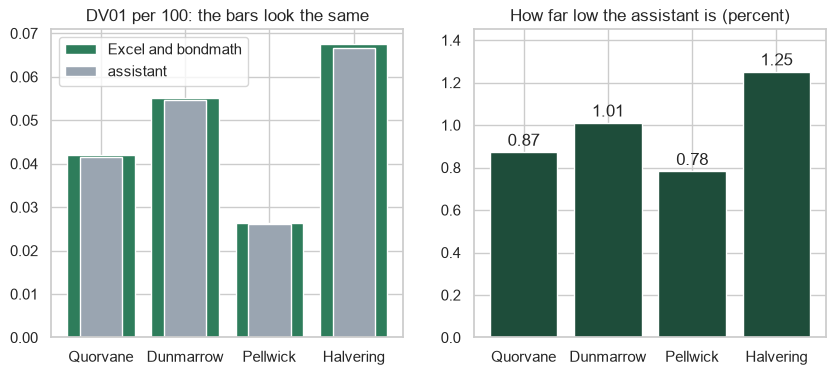

In [25]:
names = bonds['issuer'].str.split().str[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(names, bonds['excel_dv01'], label='Excel and bondmath')
axes[0].bar(names, bonds['assistant_dv01'], width=0.5, label='assistant')
axes[0].set_title('DV01 per 100: the bars look the same')
axes[0].legend(loc='upper left')
bars = axes[1].bar(names, bonds['gap_pct'], color='#1E4D3A')
axes[1].bar_label(bars, fmt='%.2f', padding=2)
axes[1].set_title('How far low the assistant is (percent)')
axes[1].set_ylim(0, 1.45)
plt.show()

**Excel side by side.** The bug's Excel twin drops the accrued B2 from Course 2's DV01 cell for Quorvane (B1 `PRICE`, B4 `MDURATION`).

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">DV01 per 100, Course 2's cell</td><td align="left"><code>bondmath.dv01(...)</code></td><td align="left"><code>=B4*(B1+B2)/10000</code></td><td align="left">0.04190266430092781</td></tr>
<tr><td align="left">The assistant's DV01</td><td align="left"><code>assistant_dv01(...)</code></td><td align="left"><code>=B4*B1/10000</code></td><td align="left">0.0415368812533095</td></tr>
</table>
<br clear="left">

Pick test dates where a mistake would show: a settlement between coupons, a month ending on a weekend, the start of a series.
The fix is `bondmath.dv01`, already tested.

**The assistant's DV01 is about 1 percent low on every bond, and only a test between coupons, against a reference you trust, shows it.**

## 13.5 What Goes Into the Chat

![Your text, the line that failed, the error's last line, five synthetic rows, your versions and the question, passes through redact, which turns an api_key value into three stars and your home folder into a tilde, then through safe_to_paste, which stops on an api_key value, a 32-character token or your home folder, and only then reaches the chat. Below, Course 1's list still in force, client names, positions and trades, anything from your employer, credentials, and the three Course 3 adds, a key, a URL or message that holds a key, a path with your user name](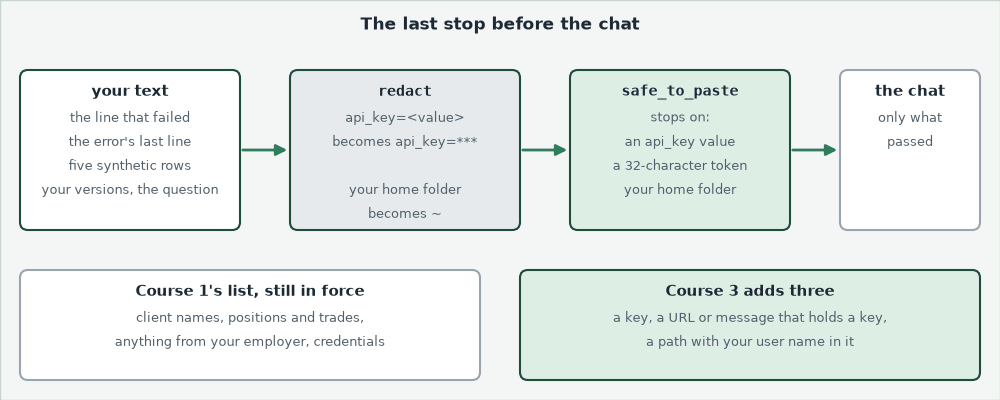)

Course 1's list of what never goes into an AI tool still holds.
Course 3 adds three things that can ride inside an innocent error message.
Paste only what the picture's first box lists.

### A Message Built to Be Pasted

In [26]:
try:
    md.get_secret('NO_SUCH_SECRET', env_file='.env')
except RuntimeError as error:
    print(error)

Secret NO_SUCH_SECRET not found. Looked in: the environment variable NO_SUCH_SECRET, Colab's Secrets panel, and the file .env given as env_file.


Notebook 01 wrote it to name the secret and the places looked: no value, no folder.

### A Message That Is Not

Notebook 02 named `raise_for_status` and never called it: its message carries the whole request URL, key included.
Here is that message for a FRED error with the course's fake key, typed as text.

In [27]:
http_message = ('400 Client Error: Bad Request for url: '
                'https://api.stlouisfed.org/fred/series/observations?series_id=DGS10'
                '&api_key=fakefakefakefakefakefakefakefake&file_type=json')

### `redact` and `safe_to_paste`

`redact` swaps a key's value for `***` and your home folder for `~`; `safe_to_paste` stops while either is still there, or a 32-character token, the shape notebook 02 scanned for.

In [28]:
# the name of the URL parameter that carries a FRED key
KEY_PARAM = 'api_key'


def redact(text):
    """Text with the value of every api_key replaced by *** and your home folder by ~."""
    text = re.sub(KEY_PARAM + r'=[^&\s]+', KEY_PARAM + '=***', text)
    return text.replace(str(Path.home()), '~')


def safe_to_paste(text):
    """Stop if the text holds an api_key value, a 32-character token, or your home folder."""
    assert not re.search(KEY_PARAM + r'=[^*]', text), 'an api_key value'
    assert not re.search(r'\b[a-z0-9]{32}\b', text), 'a 32-character token that could be a key'
    assert str(Path.home()) not in text, 'your home folder, which holds your user name'

In [29]:
print(redact(http_message))
safe_to_paste(redact(http_message))
# a file in your home folder, as a traceback would show it
env_path = str(Path.home() / 'projects' / 'my_bondmath' / '.env')
print('the home folder left after redact:', str(Path.home()) in redact(env_path))

400 Client Error: Bad Request for url: https://api.stlouisfed.org/fred/series/observations?series_id=DGS10&api_key=***&file_type=json
the home folder left after redact: False


In [30]:
# the message as it came, before redact
safe_to_paste(http_message)

AssertionError: an api_key value

### A Real Question, Put Together

Q. `change_bp` refuses a series. Put together what you would paste.

In [31]:
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date')
# five days of the synthetic high yield spread, in bp, with one day blanked
gappy = spreads['hy_spread_bp'].loc['2026-09-28':'2026-10-02'].copy()
gappy.loc['2026-09-30'] = float('nan')
try:
    md.change_bp(gappy, percent_units=False)
except ValueError as error:
    error_line = f'ValueError: {error}'

In [32]:
# .to_csv() with no file name returns the text instead of writing a file
paste = '\n'.join(['This line fails:', "md.change_bp(gappy, percent_units=False)",
                   redact(error_line),
                   'Five rows of synthetic data, spreads in bp:', gappy.to_csv().strip(),
                   'Why is it refused? A missing day may never be filled.'])
safe_to_paste(paste)
print(paste)

This line fails:
md.change_bp(gappy, percent_units=False)
ValueError: series has 1 missing values; drop them first with .dropna()
Five rows of synthetic data, spreads in bp:
date,hy_spread_bp
2026-09-28,320.0
2026-09-29,331.1
2026-09-30,
2026-10-01,330.0
2026-10-02,328.7
Why is it refused? A missing day may never be filled.


When a library may be the cause, add your versions: Course 1's `platform.python_version()`, and `pd.__version__`, the pandas running.
Leave the rule out and a common answer is to fill the gap, which the course's conventions forbid.

**Paste the line, the error, five synthetic rows and the rule, run it through `safe_to_paste` first, and the key and your user name never leave your machine.**

## 13.6 A Package That Does Not Exist

The note's colleague also forwarded this, written for this course in the style of an AI assistant's answer:

> For DV01 straight from FRED data, use the `fredbond-tools` package. Install it with pip, then `import fredbond_tools as fbt` and call `fbt.curve_dv01(series_id="DGS10", maturity_years=5)`.

The name is invented for this course: PyPI, Course 1's Day 0 catalogue that pip installs from, had no project called `fredbond-tools` when checked on 2026-11-08.

### Try the Import

In [33]:
import fredbond_tools

ModuleNotFoundError: No module named 'fredbond_tools'

![Five steps. 1, the assistant names fredbond-tools. 2, PyPI has no such project: the name is free. Dashed, what can happen once the name is suggested: 3, a stranger registers the name with their code inside; 4, pip install downloads and runs their code; 5, import runs it again, with your access. A green box, check before pip install, the PyPI page and python -m pip index versions fredbond-tools, points at the gap before step 4: stop here](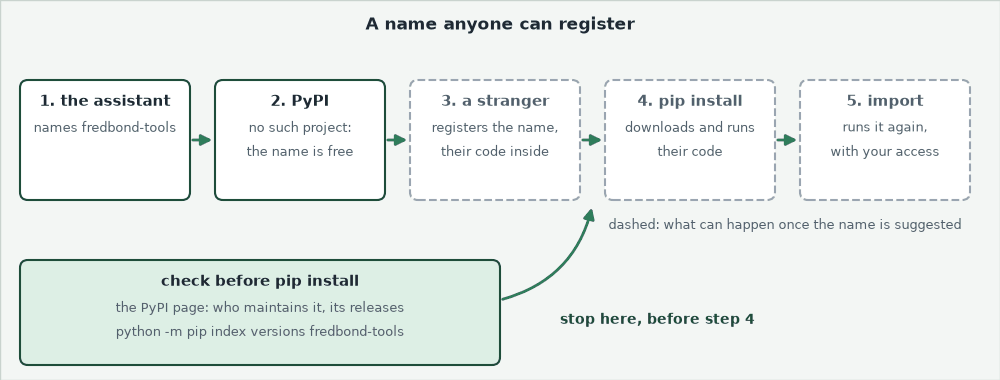)

Course 1's Day 0 met this error; the tempting next step is `pip install`.
Anyone can register an unused name on PyPI, and `pip install` and `import` both run its owner's code.
Check the name first, in PowerShell, shown here and never run by the notebook:

```powershell
# the PyPI page first: https://pypi.org/project/fredbond-tools/
# pip asks PyPI which versions exist, and installs nothing
python -m pip index versions fredbond-tools
python -m pip index versions requests
```


On 2026-11-08 the first printed `ERROR: No matching distribution found for fredbond-tools`, and the second began `requests (2.34.2)`.
No page, or a page made last week, is a reason to stop; at work, your firm decides what may be installed.

### Look Without Importing

In [34]:
import importlib.util

# find_spec finds a module and runs none of its code; None means Python cannot import it
for name in ['fredbond_tools', 'pandas']:
    print(name, 'installed:', importlib.util.find_spec(name) is not None)

fredbond_tools installed: False
pandas installed: True


The import name has an underscore, `fredbond_tools`; the name pip uses has a hyphen, `fredbond-tools`.

### An Argument That Does Not Exist

An assistant can also call a real function with an argument it never had: a **hallucinated argument**.

In [35]:
import inspect

# inspect.signature lists the arguments a function really takes
parameters = list(inspect.signature(pd.Series.resample).parameters)
print(parameters)
print("'how' among them:", 'how' in parameters)

['self', 'rule', 'closed', 'label', 'convention', 'on', 'level', 'origin', 'offset', 'group_keys']
'how' among them: False


Exercise 4 meets one.

**Check a name on PyPI before installing it, and an argument with `inspect.signature` before trusting it: an assistant can invent both.**

## 13.7 JSON Replies and `parse_json_reply`

![parse_json_reply checks the shape: the reply text goes through json.loads, then is it an object, then is every field asked for there, and comes out a dict; each check that fails ends in a dashed ValueError box, not valid JSON, not an object, names what is missing. From the dict an arrow goes down to your conventions, which check the content: units are bp, min_periods equals the window, today is in the window](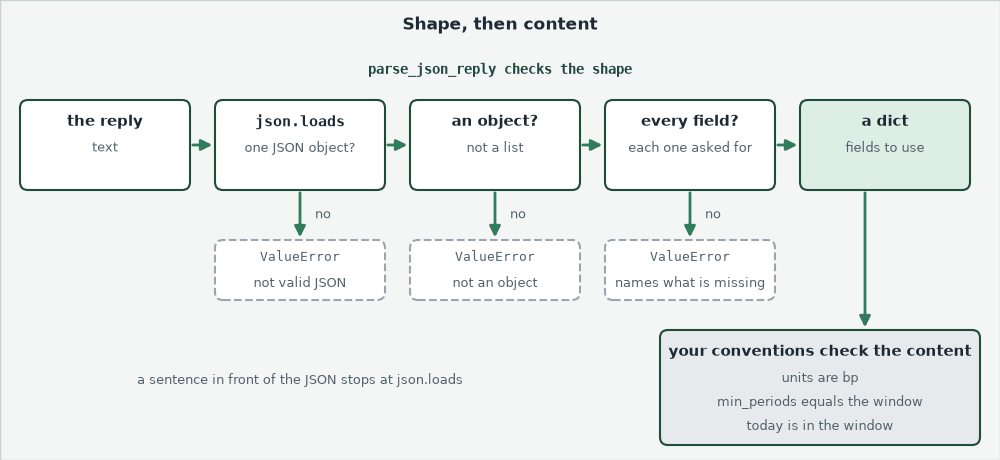)

Notebook 02 read JSON from FRED.
It is also what an assistant answers in when a program, not a person, reads the reply.
Replies often arrive with a sentence in front, or a field missing, so the reply is checked before any field is used.

### The Docstring, the Function, and Three Tests

The docstring promises three things: the whole reply is one JSON object, extra fields are kept, and a `ValueError` names every missing field.
`json.JSONDecodeError` is the error notebook 02 read in a traceback: its `msg`, `lineno` and `colno` say what went wrong and where, and `raise ... from error` keeps it attached as the cause.
`import json` sits where today's code starts.

In [36]:
%%writefile -a marketdata.py


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply

Appending to marketdata.py


In [37]:
%%writefile -a test_marketdata.py


def test_parse_json_reply_fields():
    text = '{"series_id": "DGS10", "units": "percent", "window_rows": 252, "note": "extra fields are kept"}'
    reply = md.parse_json_reply(text, ["series_id", "units", "window_rows"])
    assert reply["window_rows"] == 252 and reply["note"] == "extra fields are kept"


def test_parse_json_reply_missing_field_raises():
    with pytest.raises(ValueError, match="units, window_rows"):
        md.parse_json_reply('{"series_id": "DGS10"}', ["series_id", "units", "window_rows"])


def test_parse_json_reply_not_json_raises():
    # prose around the JSON, as assistants often add
    with pytest.raises(ValueError):
        md.parse_json_reply('Sure! Here is the JSON: {"series_id": "DGS10"}', ["series_id"])
    with pytest.raises(ValueError):
        md.parse_json_reply('["DGS10", "DGS2"]', ["series_id"])

Appending to test_marketdata.py


In [38]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 0.50s



### Three Replies

The prompt asked for the definition behind the 63-row volatility of the 10 Yr, as one JSON object with five fields.

In [39]:
importlib.reload(md)
FIELDS = ['series_id', 'units', 'window_rows', 'min_periods', 'includes_today']
# three replies, written for this course in the style of an AI assistant's answer
clean = ('{"series_id": "DGS10", "units": "bp", "window_rows": 63, "min_periods": 63, '
         '"includes_today": true}')
replies = {'clean': clean,
           'with a sentence': 'Sure! Here is the definition you asked for:\n' + clean,
           'missing a field': clean.replace(' "min_periods": 63,', '')}
for label, text in replies.items():
    try:
        print(f'{label}: ok, {len(md.parse_json_reply(text, FIELDS))} fields')
    except ValueError as error:
        print(f'{label}: ValueError: {error}')

clean: ok, 5 fields
with a sentence: ValueError: the reply is not valid JSON: Expecting value at line 1, column 1
missing a field: ValueError: the reply is missing min_periods


**Predict 3**

Q. A reply comes back with `"min_periods": null`. `parse_json_reply`:

A) passes it: the field is there
B) raises `ValueError`: the field is missing
C) raises `ValueError`: not valid JSON

### A Null Field

In [40]:
null_reply = clean.replace('"min_periods": 63', '"min_periods": null')
reply = md.parse_json_reply(null_reply, FIELDS)
print(f"passed, {len(reply)} fields, min_periods is {reply['min_periods']}")

passed, 5 fields, min_periods is None


A: JSON's `null` arrives in Python as `None`, and `true` as `True`.
The shape passes, and the value says nothing.

### Shape, Then Content

In [41]:
reply = md.parse_json_reply(replies['clean'], FIELDS)
# the course's conventions: changes in bp, no partial windows, today in the window
assert reply['units'] == 'bp', 'volatility of changes is in bp'
assert reply['min_periods'] == reply['window_rows'], 'no partial windows'
assert reply['includes_today'] is True, 'the window includes the current row'
print(f"{reply['series_id']}: {reply['window_rows']} rows, min_periods {reply['min_periods']}")

DGS10: 63 rows, min_periods 63


**`parse_json_reply` checks the shape and your conventions check the content: both are tests, and both run on your machine, not in the assistant.**

## 13.8 An Assistant's Patch, Reviewed With Git

The module is done for the day: commit it, then answer the note's last ask.

### Read the Diff, Commit the Day

In [42]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Notebook 13: parse_json_reply"

 M marketdata.py
 M test_marketdata.py
 marketdata.py      | 25 +++++++++++++++++++++++++
 test_marketdata.py | 19 +++++++++++++++++++
 2 files changed, 44 insertions(+)


![A file, suggestion.patch, with an @@ line, lines kept, a line taken out marked minus and two lines put in marked plus: Course 2's diff hunk saved to a file. Five steps beside it: git apply --check, does it fit, changes nothing; git apply, changes marketdata.py; git diff, read every minus and plus line; pytest, the judge, do the tests still pass; git restore marketdata.py, back to the last commit](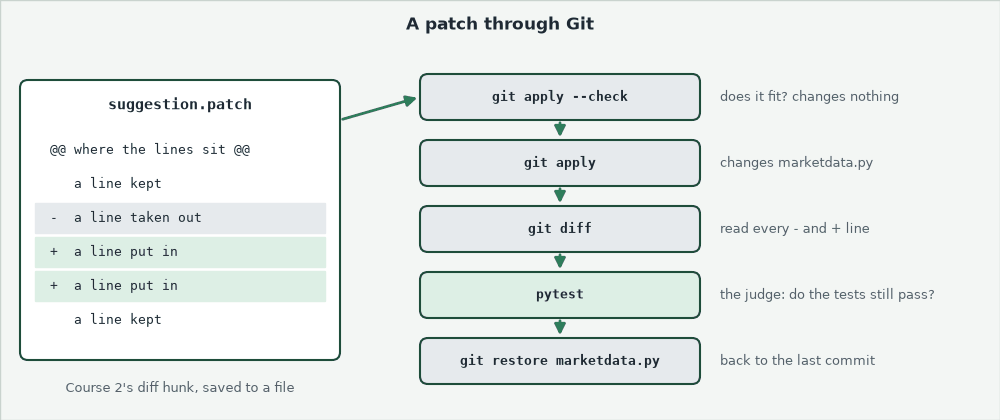)

A **patch** is Course 2's diff hunk saved to a file: the lines to take out (`-`), the lines to put in (`+`), and a few unchanged lines around them so Git can find the place.

### The Patch

It changes `parse_json_reply` "so a reply with prose around it still parses": written for this course in the style of an AI assistant's answer.

In [43]:
%%writefile suggestion.patch
--- a/marketdata.py
+++ b/marketdata.py
@@ -623,9 +623,10 @@
     Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
     (the message names every missing field).
     """
-    # parse the reply; a reply with prose around the JSON fails here
+    # find the JSON object inside the reply, so a reply with prose around it still parses
+    start, end = text.find("{"), text.rfind("}")
     try:
-        reply = json.loads(text)
+        reply = json.loads(text[start:end + 1])
     except json.JSONDecodeError as error:
         raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
     # an object, not a list or a bare number

Writing suggestion.patch


### Check, Apply, Read

In [44]:
# --check tries the patch without changing anything, and prints nothing when it fits
!git -C "{work}" apply --check suggestion.patch

In [45]:
!git -C "{work}" apply suggestion.patch
!git -C "{work}" diff

diff --git a/marketdata.py b/marketdata.py
index 29a7ce5..d82290a 100644
--- a/marketdata.py
+++ b/marketdata.py
@@ -623,9 +623,10 @@ def parse_json_reply(text: str, required: list[str]) -> dict:
     Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
     (the message names every missing field).
     """
-    # parse the reply; a reply with prose around the JSON fails here
+    # find the JSON object inside the reply, so a reply with prose around it still parses
+    start, end = text.find("{"), text.rfind("}")
     try:
-        reply = json.loads(text)
+        reply = json.loads(text[start:end + 1])
     except json.JSONDecodeError as error:
         raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
     # an object, not a list or a bare number


Two lines out, three in: the function now cuts the text from the first `{` to the last `}` before reading it.

**Predict 4**

Q. Run the 51 tests on the patched module:

A) all pass: the patch only adds a fallback
B) one test fails
C) every `parse_json_reply` test fails

### Run the Tests on the Patched Module

In [46]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider',
           '--tb=no', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................................................F                      [100%]
=========================== short test summary info ===========================
FAILED test_marketdata.py::test_parse_json_reply_not_json_raises - Failed: DID NOT RAISE ValueError
1 failed, 50 passed in 0.50s



B: the patch changed what the function promises.
The docstring says the whole reply is one JSON object, and the test written from it holds the function to that.
A reply that ignored "nothing else" may have ignored other instructions too, so the course says no.

### Throw It Away

In [47]:
# restore puts the file back as the last commit has it
!git -C "{work}" restore marketdata.py
!git -C "{work}" status --short

?? suggestion.patch


In [48]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 0.50s



**The patch applied cleanly and broke a promise the tests hold: refuse it, and `git restore` puts the module back as committed.**

## Bring It Home

Copy the work folder's two files into your own `my_bondmath` folder, test them there, and commit.
The copy replaces your files, so anything of your own must be in the work folder first.
Every data file the tests read is already there.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_13_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
python -m pytest -q test_marketdata.py
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Notebook 13: parse_json_reply"
```

pytest shows 51 passed.
Two habits to keep: run `safe_to_paste` before you paste, and look a name up on PyPI before you install it.

In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Write a prompt as a spec: the docstring, the conventions that apply, and a test.
* Run an assistant's code against your functions and Excel's values, at the start of a series too.
* Check a chart by reading its label and its line as data.
* Test an assistant's bond code against `bondmath` on dates where a mistake would show.
* Redact a key and your home folder, and check text with `safe_to_paste` before you paste it.
* Check a package name on PyPI and an argument with `inspect.signature`.
* Check a JSON reply's shape with `parse_json_reply` and its content with your conventions.
* Review a patch with `git apply --check`, `git diff` and the tests, and undo it with `git restore`.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Every assistant answer below was written for this course in the style of an AI assistant's answer.
Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`.

In [49]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

The prompt carried the docstring of your own `md.align` (notebook 03), which says "Nothing is filled." This came back.

Q. Run `md.align` and `assistant_align` on `pair` with `how='outer'`. Store in **ex1_filled** how many values the assistant's answer holds where `md.align` leaves `NaN`, and in **ex1_date** that date as text, `'YYYY-MM-DD'`.

In [50]:
# written for this course in the style of an AI assistant's answer
def assistant_align(series, how='inner'):
    """Several dated series side by side, one column each, joined on date. Nothing is filled."""
    # join every series on date; join= says which dates to keep, as align's how= does
    frame = pd.concat(series, axis=1, join=how)
    # fill the gaps from the day before, so every column has a value on every date
    return frame.ffill()

In [51]:
five_sep = curve['5 Yr'].loc['2026-09']
# the synthetic high yield spread for September, with one day missing
hy_sep = spreads['hy_spread_bp'].loc['2026-09'].drop(pd.Timestamp('2026-09-15'))
pair = {'5 Yr': five_sep, 'hy_spread_bp': hy_sep}
ex1_filled = ...
ex1_date = ...

In [52]:
check('Exercise 1 values filled', ex1_filled, 1)
check('Exercise 1 the date', ex1_date, '2026-09-15')

Exercise 1 values filled: not attempted yet
Exercise 1 the date: not attempted yet


### Exercise 2

Q. A reply came back for the 21-row volatility of the 2 Yr, asked for with 13.7's five `FIELDS`. Check it with `md.parse_json_reply`, catch the `ValueError`, and store its message, as text, in **ex2_message**.

In [53]:
# written for this course in the style of an AI assistant's answer
ex2_reply = '{"series_id": "DGS2", "units": "bp", "window_rows": 21, "includes_today": true}'
ex2_message = ...

In [54]:
check('Exercise 2 the message', ex2_message, 'the reply is missing min_periods')

Exercise 2 the message: not attempted yet


### Exercise 3

Q. Add `is_installed(package)` to the module, docstring first: `True` when `importlib.util.find_spec` finds `package`, an import name such as `fredbond_tools`, and `ValueError` for an empty name or one with a hyphen. Add `test_is_installed` for `'json'`, `'fredbond_tools'` and the `ValueError`. Run pytest, reload, and store `[md.is_installed('pandas'), md.is_installed('fredbond_tools')]` in **ex3_answers**.

In [55]:
%%writefile -a marketdata.py


# Exercise 3: write is_installed(package) below this line

Appending to marketdata.py


In [56]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_is_installed() below this line

Appending to test_marketdata.py


In [57]:
# run pytest as in the lesson, reload the module, then call your function
ex3_answers = ...

In [58]:
check('Exercise 3 pandas, then the invented package', ex3_answers, [True, False])

Exercise 3 pandas, then the invented package: not attempted yet


### Exercise 4: AI check

You gave an assistant 13.1's docstring as the prompt.
The function below came back; it holds one bug.

In [59]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def month_end_levels(series):
    """The last observation of each calendar month, labelled by the date of that observation.

    Units: unchanged. September 2026 is 2026-09-30, and January 2026 is 2026-01-30.
    """
    # resample to calendar months and keep the last value of each one
    return series.resample('ME', how='last')

Q. Before you run the test: will the function run at all? Look at the arguments of its one call.

In [60]:
# 13.1's test
result = month_end_levels(curve['10 Yr'].loc['2026'])
assert result.loc['2026-09-30'] == 5.29, 'September is wrong'
january = result.index[0]
assert january == pd.Timestamp('2026-01-30'), f'January is labelled {january.date()}'

TypeError: NDFrame.resample() got an unexpected keyword argument 'how'

Q. Read the error's last line; 13.6's `inspect.signature` lists the real arguments. 13.2 showed what `.resample('ME').last()` does to January, so that fix fails too. Fix the function until the test passes, then store the January label as text in **ex4_january** and the September level in **ex4_september**.

In [61]:
ex4_january = ...
ex4_september = ...

In [62]:
check('Exercise 4 the January label', ex4_january, '2026-01-30')
check('Exercise 4 the September level', ex4_september, 5.29)

Exercise 4 the January label: not attempted yet
Exercise 4 the September level: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Which pieces are right</td><td align="left">Answer B, the 2s10s and its daily change</td></tr>
<tr><td align="left">What is wrong with the rest</td><td align="left">A labels January by a Saturday, C gives 16 values from partial windows, the chart says percent on bp, and the DV01 runs 0.78 to 1.25 percent low</td></tr>
<tr><td align="left">The formula</td><td align="left"><code>PERCENTRANK.INC</code> differs from <code>COUNTIF</code> on 172 of 190 days</td></tr>
<tr><td align="left">What we may paste</td><td align="left">The line, the error, five synthetic rows and the rule, through <code>safe_to_paste</code></td></tr>
<tr><td align="left">The package</td><td align="left">Not on PyPI, never installed</td></tr>
<tr><td align="left">A function for JSON replies</td><td align="left"><code>parse_json_reply</code>, 51 passed</td></tr>
<tr><td align="left">The patch</td><td align="left">Refused: one test fails, and <code>git restore</code> put the module back</td></tr>
</table>
<br clear="left">

Be proud: none of it took special knowledge of AI, only a spec you wrote and tests you trust.

Next: The Daily Market Snapshot (notebook 14) puts three weeks of work on one page for any date.